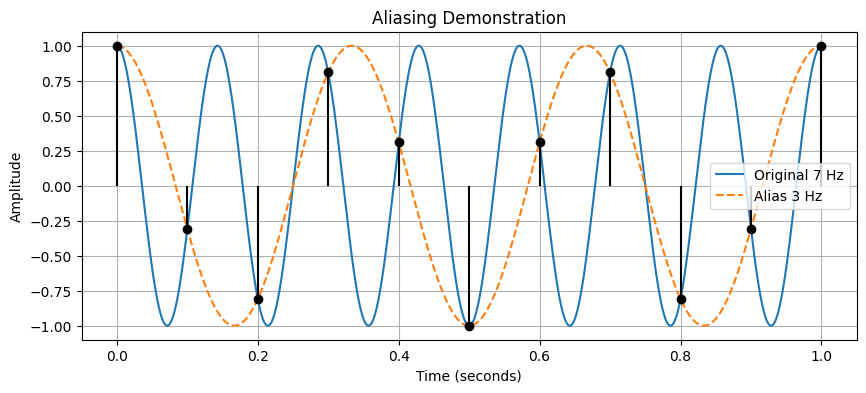

Alias frequency: 3.0 Hz


In [8]:

import numpy as np
import matplotlib.pyplot as plt

f0 = 7.0
fs = 10.0

t = np.linspace(0, 1, 2000)
n = np.arange(0, int(fs) + 1)
tn = n / fs

f_alias = abs(f0 - fs * round(f0/fs))

plt.figure(figsize=(10, 4))

plt.plot(t, np.cos(2*np.pi*f0*t), label="Original 7 Hz")
plt.plot(t, np.cos(2*np.pi*f_alias*t), "--",
         label="Alias 3 Hz")

plt.stem(tn, np.cos(2*np.pi*f0*tn),
         linefmt="k-", markerfmt="ko",
         basefmt=" ")

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Aliasing Demonstration")
plt.legend()
plt.grid()
plt.show()

print("Alias frequency:", f_alias, "Hz")


In [9]:
f0 = 7.0
sampling_rates = [10, 12, 14, 20]

for fs in sampling_rates:
    f_alias = abs(f0 - fs * round(f0/fs))
    print("Sampling frequency:", fs, "Hz",
          " | Alias frequency:", f_alias, "Hz")

Sampling frequency: 10 Hz  | Alias frequency: 3.0 Hz
Sampling frequency: 12 Hz  | Alias frequency: 5.0 Hz
Sampling frequency: 14 Hz  | Alias frequency: 7.0 Hz
Sampling frequency: 20 Hz  | Alias frequency: 7.0 Hz


In [11]:
from google.colab import files

uploaded = files.upload()

Saving my_voice.wav to my_voice.wav


In [12]:
import os

print(os.listdir())

['.config', 'my_voice.wav', 'sample_data']


In [14]:
from scipy.io import wavfile
import numpy as np

fs, x = wavfile.read("my_voice.wav")

print("Sampling Rate:", fs, "Hz")
print("Number of samples:", len(x))
print("Duration:", len(x)/fs, "seconds")

Sampling Rate: 44100 Hz
Number of samples: 221840
Duration: 5.030385487528345 seconds


In [15]:
import matplotlib.pyplot as plt

x = x.astype(float)

x2 = x[::2]
x4 = x[::4]
x8 = x[::8]

print("Original samples:", len(x))
print("Downsample x2:", len(x2))
print("Downsample x4:", len(x4))
print("Downsample x8:", len(x8))

Original samples: 221840
Downsample x2: 110920
Downsample x4: 55460
Downsample x8: 27730


In [16]:
from scipy.signal import decimate

x2_filtered = decimate(x, 2, ftype="fir")
x4_filtered = decimate(x, 4, ftype="fir")
x8_filtered = decimate(x, 8, ftype="fir")

print("Filtered x2:", len(x2_filtered))
print("Filtered x4:", len(x4_filtered))
print("Filtered x8:", len(x8_filtered))

Filtered x2: 221840
Filtered x4: 221840
Filtered x8: 221840


In [19]:
from scipy.io import wavfile
from scipy.signal import decimate

fs, x = wavfile.read("my_voice.wav")
x = x.astype(float)

x2_filtered = decimate(x, 2, ftype="fir")
x4_filtered = decimate(x, 4, ftype="fir")
x8_filtered = decimate(x, 8, ftype="fir")

print("Original:", len(x))
print("Filtered x2:", len(x2_filtered))
print("Filtered x4:", len(x4_filtered))
print("Filtered x8:", len(x8_filtered))

Original: 221840
Filtered x2: 221840
Filtered x4: 221840
Filtered x8: 221840


In [20]:
print("Shape:", x.shape)
print("Data type:", x.dtype)
print("First 10 samples:", x[:10])

Shape: (221840, 2)
Data type: float64
First 10 samples: [[0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]
 [0. 0.]]


In [21]:
from scipy.io import wavfile
from scipy.signal import decimate
import numpy as np

fs, audio = wavfile.read("my_voice.wav")

# Convert stereo to mono
x = audio.mean(axis=1)

print("Shape:", x.shape)
print("Sampling Rate:", fs)

Shape: (221840,)
Sampling Rate: 44100


In [22]:
from scipy.signal import decimate

x2_filtered = decimate(x, 2, ftype="fir")
x4_filtered = decimate(x, 4, ftype="fir")
x8_filtered = decimate(x, 8, ftype="fir")

print("Original:", len(x))
print("Filtered x2:", len(x2_filtered))
print("Filtered x4:", len(x4_filtered))
print("Filtered x8:", len(x8_filtered))

Original: 221840
Filtered x2: 110920
Filtered x4: 55460
Filtered x8: 27730


In [23]:
from IPython.display import Audio, display

display(Audio(x, rate=fs))

In [24]:
display(Audio(x[::8], rate=fs//8))

In [25]:
display(Audio(x8_filtered, rate=fs//8))

**Task 2.2: Hearing Aliasing – Observations**

The original audio was recorded at a sampling frequency of 44,100 Hz.

When downsampling by a factor of 8 without filtering, the new sampling frequency became 5,512.5 Hz. This may introduce aliasing because high-frequency components are not removed before downsampling.

When using an FIR low-pass filter before downsampling, high-frequency components are attenuated, reducing aliasing and improving the quality of the downsampled signal.

**Conclusion:** Anti-aliasing filtering is important before downsampling because it prevents unwanted frequency components from appearing in the lower-frequency range.

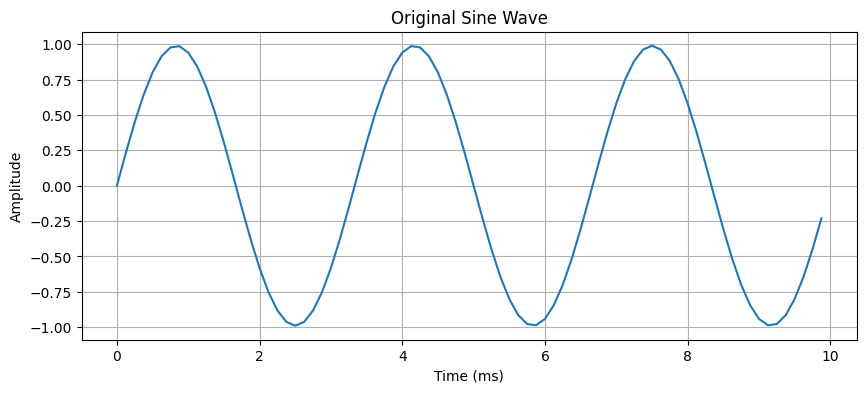

In [26]:
import numpy as np
import matplotlib.pyplot as plt

fs = 8000
t = np.arange(0, 0.01, 1/fs)

x = 0.99 * np.sin(2*np.pi*300*t)

plt.figure(figsize=(10,4))
plt.plot(t*1000, x)
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("Original Sine Wave")
plt.grid()
plt.show()

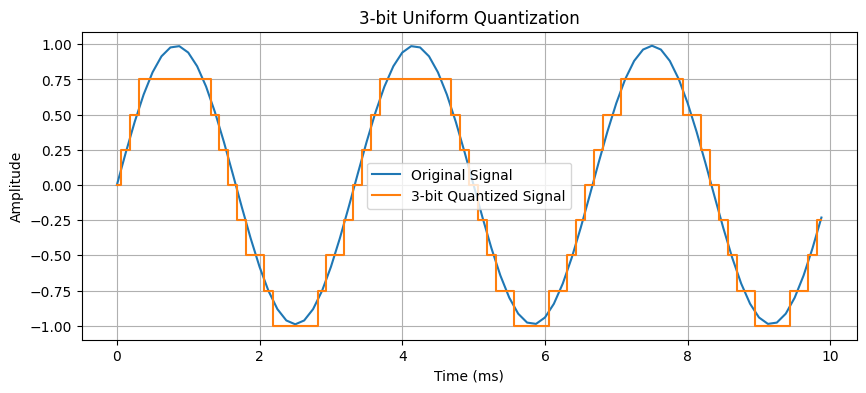

In [27]:
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / (2**bits)

    q = np.round(x / delta) * delta

    return np.clip(q, -full_scale, full_scale - delta)


xq = quantize(x, 3)

plt.figure(figsize=(10,4))

plt.plot(t*1000, x, label="Original Signal")

plt.step(t*1000, xq, where="mid",
         label="3-bit Quantized Signal")

plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("3-bit Uniform Quantization")
plt.legend()
plt.grid()
plt.show()

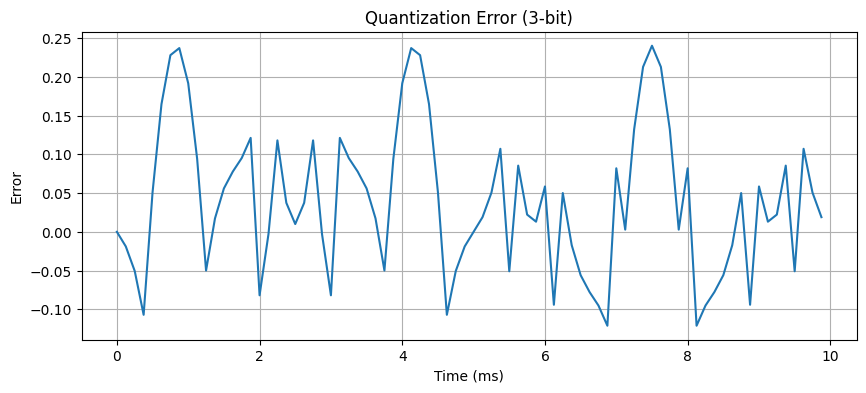

Maximum error: 0.24


In [28]:
error = x - xq

plt.figure(figsize=(10,4))

plt.plot(t*1000, error)

plt.xlabel("Time (ms)")
plt.ylabel("Error")
plt.title("Quantization Error (3-bit)")
plt.grid()
plt.show()

print("Maximum error:", np.max(np.abs(error)))

In [29]:
signal_power = np.mean(x**2)
noise_power = np.mean(error**2)

sqnr = 10 * np.log10(signal_power / noise_power)

print("Signal Power:", signal_power)
print("Noise Power:", noise_power)
print("SQNR:", sqnr, "dB")

Signal Power: 0.4900500000000002
Noise Power: 0.010661475691083494
SQNR: 16.624230725048236 dB


In [30]:
bits_list = [2, 4, 6, 8, 10, 12, 14, 16]

measured_sqnr = []
theoretical_sqnr = []

for bits in bits_list:
    xq_test = quantize(x, bits)

    error_test = x - xq_test

    signal_power = np.mean(x**2)
    noise_power = np.mean(error_test**2)

    measured = 10 * np.log10(signal_power / noise_power)
    theoretical = 6.02 * bits + 1.76

    measured_sqnr.append(measured)
    theoretical_sqnr.append(theoretical)

    print(bits, "bits:", round(measured, 2),
          "dB | Theory:", round(theoretical, 2), "dB")

2 bits: 9.6 dB | Theory: 13.8 dB
4 bits: 23.58 dB | Theory: 25.84 dB
6 bits: 36.81 dB | Theory: 37.88 dB
8 bits: 48.93 dB | Theory: 49.92 dB
10 bits: 62.81 dB | Theory: 61.96 dB
12 bits: 72.84 dB | Theory: 74.0 dB
14 bits: 88.13 dB | Theory: 86.04 dB
16 bits: 98.91 dB | Theory: 98.08 dB


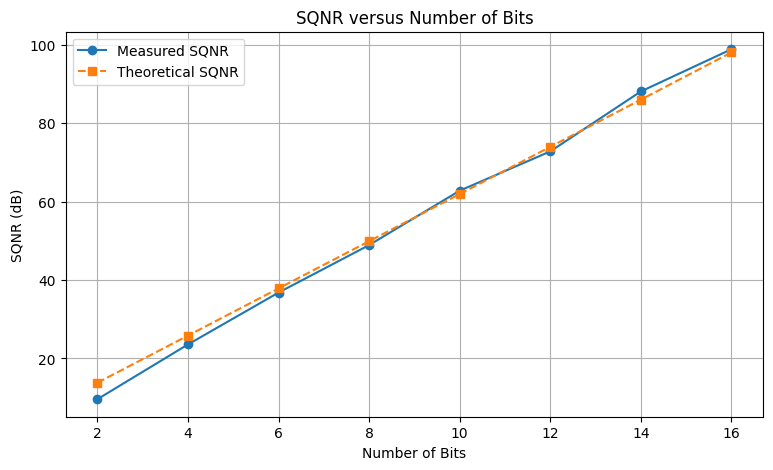

In [31]:
plt.figure(figsize=(9,5))

plt.plot(bits_list, measured_sqnr, 'o-', label="Measured SQNR")
plt.plot(bits_list, theoretical_sqnr, 's--', label="Theoretical SQNR")

plt.xlabel("Number of Bits")
plt.ylabel("SQNR (dB)")
plt.title("SQNR versus Number of Bits")
plt.legend()
plt.grid()
plt.show()

**Task 2.4: SQNR Analysis**

The measured SQNR increases as the number of quantization bits increases. This means that increasing the number of bits reduces quantization noise and improves signal quality.

The theoretical SQNR increases by approximately 6.02 dB for every additional bit.

The measured results are generally close to the theoretical values, although small differences occur due to the actual signal amplitude and quantization error.

**Conclusion:** Increasing the number of bits improves the accuracy of signal quantization and reduces quantization noise.

In [32]:
# Normalize voice signal
x_voice = x / np.max(np.abs(x))

# Quantize using different bit levels
voice_4bit = quantize(x_voice, 4)
voice_8bit = quantize(x_voice, 8)
voice_12bit = quantize(x_voice, 12)

print("Voice quantization completed!")
print("4-bit samples:", len(voice_4bit))
print("8-bit samples:", len(voice_8bit))
print("12-bit samples:", len(voice_12bit))

Voice quantization completed!
4-bit samples: 80
8-bit samples: 80
12-bit samples: 80


In [33]:
from IPython.display import Audio, display

display(Audio(voice_4bit, rate=fs))

In [34]:
display(Audio(voice_8bit, rate=fs))

In [35]:
display(Audio(voice_12bit, rate=fs))

In [36]:
def calculate_sqnr(original, quantized):
    error = original - quantized

    signal_power = np.mean(original**2)
    noise_power = np.mean(error**2)

    return 10 * np.log10(signal_power / noise_power)

sqnr_4 = calculate_sqnr(x_voice, voice_4bit)
sqnr_8 = calculate_sqnr(x_voice, voice_8bit)
sqnr_12 = calculate_sqnr(x_voice, voice_12bit)

print("4-bit SQNR:", round(sqnr_4, 2), "dB")
print("8-bit SQNR:", round(sqnr_8, 2), "dB")
print("12-bit SQNR:", round(sqnr_12, 2), "dB")

4-bit SQNR: 23.27 dB
8-bit SQNR: 49.29 dB
12-bit SQNR: 75.05 dB


# WEEK 2: ANALYSIS QUESTIONS

### Question 1: Explain why a 7 Hz tone appears as 3 Hz when sampled at 10 Hz.

**Answer:**

The sampling frequency is 10 Hz.

According to the Nyquist theorem, the Nyquist frequency is:

fN = fs / 2

fN = 10 / 2 = 5 Hz

Since the original signal frequency (7 Hz) is greater than the Nyquist frequency (5 Hz), aliasing occurs.

The alias frequency is calculated as:

f_alias = |f0 - fs|

f_alias = |7 - 10| = 3 Hz

Therefore, the 7 Hz signal appears as a 3 Hz signal after sampling.

### Question 2: Why can't aliasing in the naïve version be removed afterwards?

**Answer:**

Aliasing cannot easily be removed after sampling because different original frequencies can produce the same sampled signal.

The original frequency information is lost during sampling.

To prevent aliasing, an anti-aliasing low-pass filter must be applied before downsampling.

### Question 3: By how much does SQNR change when one bit is added? Does the measurement agree?

**Answer:**

The theoretical SQNR increases by approximately 6.02 dB for every additional bit.

The relationship is:

SQNR = 6.02B + 1.76 dB

Increasing the number of bits reduces quantization noise and improves signal quality.

The measured results generally show an increasing SQNR as the number of bits increases. Small differences between measured and theoretical values occur because of the actual signal amplitude, finite samples and quantization error.

### Question 4: A temperature sensor changes at most 0.1 °C/s and has a resolution of 0.01 °C over 0–100 °C. Suggest a sampling rate and number of bits.

**Answer:**

The temperature sensor changes at a maximum rate of 0.1 °C per second.

To limit the temperature change between consecutive samples to 0.01 °C:

Sampling interval = 0.01 / 0.1

Sampling interval = 0.1 seconds

Therefore:

Sampling frequency = 1 / 0.1 = 10 Hz

A sampling rate of 10 Hz is recommended.

To calculate the required number of bits:

Number of levels = 100 / 0.01

Number of levels = 10,000

B = ceil(log2(10,000))

B = 14 bits

Therefore, a 10 Hz sampling rate and a 14-bit quantizer are recommended.

A 14-bit quantizer provides 16,384 possible levels, which is sufficient for the required temperature resolution.

### Use of Artificial Intelligence (AI)

ChatGPT (OpenAI) was used as a learning support tool during this laboratory exercise. It helped in understanding Digital Signal Processing concepts, explaining Python code, troubleshooting errors, and interpreting experimental results.

All practical activities, code execution, observations, and results were performed and verified by the student. AI was used to support learning and understanding of the laboratory tasks.